In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [4]:
import glob, os

# Looks in datasets/ (running locally from the repo) and /content/ (Colab uploads).
# Also finds Colab-renamed copies like "final_training_data (1).csv".
DATA_DIRS = ["datasets", "/content/datasets", "/content", "."]

def find_file(name, required=True):
    stem, ext = os.path.splitext(name)
    for d in DATA_DIRS:
        exact = os.path.join(d, name)
        if os.path.exists(exact):
            return exact
        hits = sorted(glob.glob(os.path.join(d, stem + " (*)" + ext)))
        if hits:
            return hits[-1]
    if required:
        raise FileNotFoundError(f"Upload {name} to /content/ (Colab) or keep it in datasets/ (local).")
    return None

file_path = find_file("train_90.csv")

df = pd.read_csv(file_path)

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Dataset shape:", df.shape)
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

# Make sure the official dataset is being used


print("\nConfirmed: official 200+ -record dataset loaded.")

print("\nColumns:")
for col in df.columns:
    print("-", col)

print("\nFirst 5 records:")
display(df.head())


DATASET INFORMATION
Dataset shape: (225, 27)
Number of rows: 225
Number of columns: 27

Confirmed: official 200+ -record dataset loaded.

Columns:
- record_id
- source_file
- record_type
- platform
- source_name
- keyword
- title
- text
- url
- source_record_id
- parent_record_id
- author
- published_at
- site_or_channel
- community
- language
- score
- views
- likes
- comments_count
- shares_count
- replies_count
- detected_language
- tokens
- lemmas
- text_clean
- lang_group

First 5 records:


,record_id,source_file,record_type,platform,source_name,keyword,title,text,url,source_record_id,parent_record_id,author,published_at,site_or_channel,community,language,score,views,likes,comments_count,shares_count,replies_count,detected_language,tokens,lemmas,text_clean,lang_group
0,data14114,youtube_philippine_education_comments.csv,youtube_comment,youtube,youtube,digital education philippines,technology in education,today's tech is transforming the classroom as we know it many students can absorb subject matter...,https://www.youtube.com/watch,ugyts-gv5tz7dzdyr3p4aaabag,enrtlkqmggo,NaN,2025-11-26t16:49:08z,agileed,NaN,NaN,NaN,111891.0,3.0,12.0,NaN,0.0,english,technology education today's tech transforming classroom know students absorb subject matter mat...,technology education today' tech transform classroom know student absorb subject matter matter e...,today's tech is transforming the classroom as we know it many students can absorb subject matter...,English
1,data12313,youtube_philippine_education_comments.csv,youtube_comment,youtube,youtube,college students philippines,college bag lifestyle collegelife collegestudent univlog studytips whatsinmybag longchamp,is it too early for back to school content,https://www.youtube.com/watch,ugw-tes3liju6o5ubf54aaabag,nohg1mmg2xs,NaN,2025-08-03t12:56:04z,reve,NaN,NaN,NaN,1052951.0,123.0,277.0,NaN,16.0,english,college bag lifestyle collegelife collegestudent univlog studytips whatsinmybag longchamp early ...,college bag lifestyle collegelife collegestudent univlog studytip whatsinmybag longchamp early b...,is it too early for back to school content,English
2,data00591,tiktok-apify.csv,tiktok_video,tiktok,tiktok apify,school facilities philippines,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives a prayer from a scholar sa isang makabuluhang ...,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives a prayer from a scholar sa isang makabuluhang ...,https://www.tiktok.com/@kaalaman.politics/video/7691718583251946804,7691718583251946804,NaN,kaalaman politics,2026-10-02t06:00:00.000z,https://www.tiktok.com/@kaalaman.politics,NaN,tl,NaN,54170.0,5925.0,285.0,137.0,NaN,tagalog,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives prayer scholar isang makabuluhang sandali isan...,ud83d ude4f ud83c uddf5 ud83c ud pbbm receive prayer scholar isang makabuluhang sandali isang sc...,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives a prayer from a scholar sa isang makabuluhang ...,Tagalog
3,data09050,youtube_philippine_education_comments.csv,youtube_comment,youtube,youtube,education curriculum philippines,curriculum and the types of curriculum,thank you sir,https://www.youtube.com/watch,ugy8ai6yvtaoz4k_iod4aaabag,0mjpilnsmrc,NaN,2026-09-02t02:30:24z,sir nestor tv,NaN,NaN,NaN,7305.0,0.0,17.0,NaN,0.0,english,curriculum types curriculum thank sir,curriculum type curriculum thank sir,thank you sir,English
4,data11652,youtube_philippine_education_comments.csv,youtube_comment,youtube,youtube,college education philippines,med school in the philippines vs in the us up college of medicine grad,this is a super interesting reflection i wish we had organ-system integration at my school i'm a...,https://www.youtube.com/watch,ugx1pc2mj-2fkdiwk_z4aaabag,vw8kojzyrso,NaN,2024-07-06t04:09:43z,jasmine,NaN,NaN,NaN,2108.0,3.0,5.0,NaN,1.0,english,med school philippines vs college medicine grad super interesting reflection wish organ-system i...,med school philippines vs college medicine grad super interest reflection wish organ-system inte...,this is a super interesting reflection i wish we had organ-system integration at my school i'm a...,English


In [5]:
print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing.sort_values(
        "Missing",
        ascending=False
    )
)



MISSING VALUES


,Missing,Percentage
language,206,91.56
shares_count,206,91.56
score,160,71.11
community,143,63.56
author,141,62.67
replies_count,134,59.56
views,115,51.11
likes,115,51.11
comments_count,115,51.11
site_or_channel,82,36.44


In [6]:
print("\n" + "=" * 70)
print("SOURCE / PLATFORM COUNTS")
print("=" * 70)

print("\nOriginal source_name counts:")
display(
    df["source_name"]
    .value_counts()
)

print("\nPlatform counts:")
display(
    df["platform"]
    .value_counts()
)


SOURCE / PLATFORM COUNTS

Original source_name counts:


source_name
youtube                     91
reddit public post page     65
tiktok apify                19
reddit public search        17
www.rappler.com             13
www.philstar.com             5
interaksyon.philstar.com     5
www.manilatimes.net          4
www.deped.gov.ph             3
tribune.net.ph               3
Name: count, dtype: int64


Platform counts:


platform
youtube    91
reddit     82
web        33
tiktok     19
Name: count, dtype: int64

In [7]:
print("\n" + "=" * 70)
print("CREATING ANALYSIS TEXT")
print("=" * 70)


def get_analysis_text(row):

    record_type = row["record_type"]

    if record_type in [
        "youtube_comment",
        "reddit_comment"
    ]:

        if pd.isna(row["text"]):
            return ""

        return str(row["text"])

    elif record_type in [
        "article",
        "reddit_post"
    ]:

        if pd.isna(row["title"]):
            return ""

        return str(row["title"])

    else:

        if pd.isna(row["text"]):
            return ""

        return str(row["text"])


df["analysis_text"] = (
    df.apply(
        get_analysis_text,
        axis=1
    )
    .fillna("")
    .astype(str)
    .str.strip()
)

df = df.reset_index(drop=True)

df["text_length"] = (
    df["analysis_text"]
    .str.split()
    .str.len()
    .fillna(0)
    .astype(int)
)

print("Records retained:", len(df))
print(
    "Records with empty analysis text:",
    (df["analysis_text"] == "").sum()
)

print("\nSample of analysis text:")
display(
    df[
        [
            "record_id",
            "record_type",
            "platform",
            "title",
            "text",
            "analysis_text"
        ]
    ].head(10)
)


CREATING ANALYSIS TEXT
Records retained: 225
Records with empty analysis text: 0

Sample of analysis text:


,record_id,record_type,platform,title,text,analysis_text
0,data14114,youtube_comment,youtube,technology in education,today's tech is transforming the classroom as we know it many students can absorb subject matter...,today's tech is transforming the classroom as we know it many students can absorb subject matter...
1,data12313,youtube_comment,youtube,college bag lifestyle collegelife collegestudent univlog studytips whatsinmybag longchamp,is it too early for back to school content,is it too early for back to school content
2,data00591,tiktok_video,tiktok,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives a prayer from a scholar sa isang makabuluhang ...,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives a prayer from a scholar sa isang makabuluhang ...,ud83d ude4f ud83c uddf5 ud83c udded pbbm receives a prayer from a scholar sa isang makabuluhang ...
3,data09050,youtube_comment,youtube,curriculum and the types of curriculum,thank you sir,thank you sir
4,data11652,youtube_comment,youtube,med school in the philippines vs in the us up college of medicine grad,this is a super interesting reflection i wish we had organ-system integration at my school i'm a...,this is a super interesting reflection i wish we had organ-system integration at my school i'm a...
5,data00292,reddit_comment,reddit,nakakalungkot talaga ang lagay ng edukasyon sa pilipinas sa kamay ng mga ganitong guro,kaya ang daming bobong mabait eh,kaya ang daming bobong mabait eh
6,data00200,reddit_comment,reddit,what s really lacking in ph education that many don t seem to know,we already had essay-type questions back when i was in grade i remember struggling a lot with th...,we already had essay-type questions back when i was in grade i remember struggling a lot with th...
7,data12743,youtube_comment,youtube,magkano tuition sa dlsu,grabe ang mahal na pala id106 ang tuition lo that time -50k per term,grabe ang mahal na pala id106 ang tuition lo that time -50k per term
8,data00033,article,web,philippines still among top countries in bullying pisa,at a glance - in of filipino students reported experiencing bullying according to the programme ...,philippines still among top countries in bullying pisa
9,data14600,youtube_comment,youtube,what is the difference between online blended and hybrid learning modes - professor g mba tv,i have been searching for a clear cut demarcation between the terms you have discussed for many ...,i have been searching for a clear cut demarcation between the terms you have discussed for many ...


In [8]:
print("\n" + "=" * 70)
print("TF-IDF ANALYSIS")
print("=" * 70)

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    norm="l2"
)

tfidf_matrix = (
    tfidf_vectorizer
    .fit_transform(
        df["analysis_text"]
    )
)

print(
    "TF-IDF matrix shape:",
    tfidf_matrix.shape
)

print(
    "Number of terms:",
    len(
        tfidf_vectorizer
        .get_feature_names_out()
    )
)

feature_names = (
    tfidf_vectorizer
    .get_feature_names_out()
)

print("\nFirst 50 TF-IDF terms:")
print(feature_names[:50])



TF-IDF ANALYSIS
TF-IDF matrix shape: (225, 1597)
Number of terms: 1597

First 50 TF-IDF terms:
['2nd' '4years' '8th' '8th grade' 'ability' 'able' 'able tell' 'abroad'
 'absolutely' 'abuse' 'academic' 'academically' 'accept' 'accepted'
 'access' 'accessible' 'according' 'accountable' 'achieved' 'achievement'
 'acknowledged' 'acquired' 'act' 'act like' 'action' 'activities' 'actual'
 'actually' 'add' 'addition' 'address' 'administration' 'admission'
 'admissions' 'admit' 'admittedly' 'advantage' 'affect' 'afford' 'afraid'
 'agad' 'agad agad' 'age' 'ago' 'agree' 'agustin' 'ai' 'ako' 'ako na'
 'alam']


In [9]:
cosine_matrix = cosine_similarity(
    tfidf_matrix
)

cosine_df = pd.DataFrame(
    cosine_matrix,
    index=df["record_id"],
    columns=df["record_id"]
)

print("\nCosine similarity matrix:")
display(
    cosine_df.head()
)


Cosine similarity matrix:


record_id,data14114,data12313,data00591,data09050,data11652,data00292,data00200,data12743,data00033,data14600,data08948,data00170,data00299,data00007,data00380,data16065,data00553,data09005,data00197,data11340,data00102,data00255,data00006,data11756,data01362,data00013,data00242,data00404,data10944,data00040,data00611,data00092,data00163,data00164,data10669,data00630,data16670,data00198,data11314,data14703,data15644,data11051,data01630,data12772,data00231,data14576,data11654,data00531,data00204,data06786,data16063,data00600,data16753,data00371,data01627,data00015,data00637,data00293,data11180,data00261,data05444,data11953,data00093,data12908,data11471,data00239,data14599,data00360,data00326,data00162,data00099,data12952,data00210,data11183,data00094,data00638,data00328,data00266,data00217,data00363,data11345,data12413,data00295,data10776,data00168,data02287,data00327,data00021,data00264,data11869,data00010,data10947,data17571,data00061,data10853,data00428,data17722,data00338,data00063,data00028,data14462,data00477,data00456,data00641,data00592,data00298,data00111,data09910,data00265,data02633,data00636,data00203,data15744,data00067,data06811,data00350,data00598,data00631,data00362,data00167,data00103,data11042,data01542,data11214,data00236,data00601,data10674,data00296,data00335,data13991,data00330,data00593,data00342,data00417,data00639,data13984,data17578,data00263,data00211,data00634,data01522,data06949,data00008,data13983,data15882,data10897,data00029,data13049,data11651,data00599,data14603,data11371,data00460,data00594,data00294,data11754,data00202,data01606,data00240,data12744,data11152,data00161,data00396,data15989,data00216,data11198,data00254,data17552,data00230,data00331,data00455,data00160,data00045,data00941,data00169,data10930,data00405,data00364,data00095,data00023,data00587,data01604,data00447,data01585,data10774,data00005,data12816,data00352,data00329,data11153,data09167,data00016,data00297,data14403,data00064,data00251,data09888,data00131,data01580,data13436,data02420,data00400,data14095,data00044,data00166,data00373,data00205,data00538,data00237,data11362,data00257,data00379,data00234,data11359,data00365,data01528,data00199,data13995,data00596,data03509,data00391,data00577,data00608,data00024,data00165
record_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
data14114,1.000000,0.016902,0.009987,0.0,0.075781,0.000000,0.00000,0.000000,0.000000,0.020478,0.000000,0.033800,0.000000,0.0,0.076797,0.000000,0.000000,0.073896,0.102825,0.000000,0.072556,0.052003,0.0,0.00000,0.074986,0.000000,0.038041,0.043479,0.099094,0.047105,0.000000,0.237792,0.0,0.00000,0.049701,0.0,0.000000,0.047988,0.000000,0.000000,0.000000,0.057222,0.066552,0.051879,0.020174,0.000000,0.0,0.0,0.042475,0.057385,0.062391,0.042069,0.008762,0.016729,0.070279,0.000000,0.029133,0.0,0.0,0.000000,0.036800,0.014838,0.0,0.0,0.025978,0.038933,0.030545,0.000000,0.000000,0.013261,0.036287,0.056327,0.043232,0.0,0.000000,0.000000,0.0,0.010527,0.067657,0.045109,0.00000,0.011070,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.053910,0.000000,0.011519,0.11035,0.0,0.000000,0.034353,0.048834,0.034889,0.029107,0.0,0.0,0.095981,0.116931,0.000000,0.023739,0.000000,0.015056,0.063316,0.000000,0.042214,0.008484,0.004832,0.014244,0.018102,0.118421,0.010211,0.025485,0.0,0.000000,0.011258,0.018214,0.000000,0.067062,0.00000,0.006741,0.135146,0.0,0.013809,0.012040,0.088159,0.007530,0.000000,0.049334,0.025876,0.003785,0.000000,0.000000,0.0,0.066893,0.000000,0.138852,0.065467,0.015346,0.09453,0.0,0.060014,0.0,0.009368,0.025885,0.010983,0.025436,0.0,0.0,0.020976,0.017361,0.0,0.112492,0.077607,0.042441,0.000000,0.000000,0.000000,0.0,0.0,0.020653,0.008107,0.019738,0.00000,0.000000,0.019523,0.0,0.000000,0.014401,0.084316,0.000000,0.078804,0.034403,0.028162,0.0,0.0,0.0,0.020700,0.0,0.044956,0.008654,0.0,0.00

In [10]:
euclidean_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    norm=None
)

euclidean_tfidf_matrix = (
    euclidean_vectorizer
    .fit_transform(
        df["analysis_text"]
    )
)

euclidean_matrix = euclidean_distances(
    euclidean_tfidf_matrix
)

euclidean_df = pd.DataFrame(
    euclidean_matrix,
    index=df["record_id"],
    columns=df["record_id"]
)

print("\nEuclidean distance matrix:")
display(
    euclidean_df.head()
)


Euclidean distance matrix:


record_id,data14114,data12313,data00591,data09050,data11652,data00292,data00200,data12743,data00033,data14600,data08948,data00170,data00299,data00007,data00380,data16065,data00553,data09005,data00197,data11340,data00102,data00255,data00006,data11756,data01362,data00013,data00242,data00404,data10944,data00040,data00611,data00092,data00163,data00164,data10669,data00630,data16670,data00198,data11314,data14703,data15644,data11051,data01630,data12772,data00231,data14576,data11654,data00531,data00204,data06786,data16063,data00600,data16753,data00371,data01627,data00015,data00637,data00293,data11180,data00261,data05444,data11953,data00093,data12908,data11471,data00239,data14599,data00360,data00326,data00162,data00099,data12952,data00210,data11183,data00094,data00638,data00328,data00266,data00217,data00363,data11345,data12413,data00295,data10776,data00168,data02287,data00327,data00021,data00264,data11869,data00010,data10947,data17571,data00061,data10853,data00428,data17722,data00338,data00063,data00028,data14462,data00477,data00456,data00641,data00592,data00298,data00111,data09910,data00265,data02633,data00636,data00203,data15744,data00067,data06811,data00350,data00598,data00631,data00362,data00167,data00103,data11042,data01542,data11214,data00236,data00601,data10674,data00296,data00335,data13991,data00330,data00593,data00342,data00417,data00639,data13984,data17578,data00263,data00211,data00634,data01522,data06949,data00008,data13983,data15882,data10897,data00029,data13049,data11651,data00599,data14603,data11371,data00460,data00594,data00294,data11754,data00202,data01606,data00240,data12744,data11152,data00161,data00396,data15989,data00216,data11198,data00254,data17552,data00230,data00331,data00455,data00160,data00045,data00941,data00169,data10930,data00405,data00364,data00095,data00023,data00587,data01604,data00447,data01585,data10774,data00005,data12816,data00352,data00329,data11153,data09167,data00016,data00297,data14403,data00064,data00251,data09888,data00131,data01580,data13436,data02420,data00400,data14095,data00044,data00166,data00373,data00205,data00538,data00237,data11362,data00257,data00379,data00234,data11359,data00365,data01528,data00199,data13995,data00596,data03509,data00391,data00577,data00608,data00024,data00165
record_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
data14114,0.000000,36.441465,52.379247,36.037168,64.215611,37.315752,44.718067,38.910619,36.818795,38.904031,40.495565,48.595488,61.226114,36.238347,74.609227,36.450624,36.631317,38.389895,53.020503,44.807716,36.420005,42.348359,36.309696,36.907604,77.348556,38.361806,52.894391,39.077955,52.113991,36.754700,37.213023,34.759736,36.779153,41.990445,44.384226,37.728944,36.624076,39.967271,36.067636,35.714574,35.625977,36.676079,51.061746,37.025957,42.113757,37.282378,35.994942,35.897660,51.761443,56.168099,38.128913,36.792293,45.444995,105.718971,80.709819,37.948056,92.502495,36.337664,38.743998,36.977671,82.447862,62.783035,35.876062,35.917560,51.816169,42.404982,36.732787,41.866708,43.217848,37.093189,36.292454,65.817235,62.153000,39.899374,36.799467,44.914344,37.836654,38.066716,47.215261,37.663516,41.955884,41.934052,39.045787,36.413723,37.572700,40.844914,36.238347,36.857810,37.571349,64.028005,37.640240,180.456530,35.682292,37.498109,66.708833,36.901941,60.403007,50.752247,36.884627,36.754661,36.451433,36.685975,36.601185,36.138050,54.590161,42.166802,36.714424,58.571004,36.330726,62.467167,39.444494,46.799032,36.868598,36.306156,66.751533,69.961622,43.234556,36.767770,41.165247,45.408829,36.294938,41.283674,165.078899,37.283896,41.637554,35.526840,36.547742,42.176848,44.255206,55.060692,55.487535,41.962271,46.191923,41.185354,75.131897,36.885496,37.187927,35.917560,61.417485,38.239498,83.004247,103.891541,36.665101,36.034662,35.521096,54.555933,36.087505,54.310860,44.336800,37

In [11]:
print("\n" + "=" * 70)
print("JACCARD SIMILARITY")
print("=" * 70)


def create_word_set(text):

    return set(
        re.findall(
            r"\b\w+\b",
            text.lower()
        )
    )


word_sets = [
    create_word_set(text)
    for text in df["analysis_text"]
]


def jaccard_similarity(set_a, set_b):

    union = set_a | set_b

    if len(union) == 0:
        return 1.0

    return (
        len(set_a & set_b)
        /
        len(union)
    )


n = len(word_sets)

jaccard_matrix = np.zeros(
    (n, n)
)

for i in range(n):

    for j in range(i, n):

        score = jaccard_similarity(
            word_sets[i],
            word_sets[j]
        )

        jaccard_matrix[i, j] = score
        jaccard_matrix[j, i] = score


jaccard_df = pd.DataFrame(
    jaccard_matrix,
    index=df["record_id"],
    columns=df["record_id"]
)

print("Jaccard similarity matrix:")
display(
    jaccard_df.head()
)


JACCARD SIMILARITY
Jaccard similarity matrix:


record_id,data14114,data12313,data00591,data09050,data11652,data00292,data00200,data12743,data00033,data14600,data08948,data00170,data00299,data00007,data00380,data16065,data00553,data09005,data00197,data11340,data00102,data00255,data00006,data11756,data01362,data00013,data00242,data00404,data10944,data00040,data00611,data00092,data00163,data00164,data10669,data00630,data16670,data00198,data11314,data14703,data15644,data11051,data01630,data12772,data00231,data14576,data11654,data00531,data00204,data06786,data16063,data00600,data16753,data00371,data01627,data00015,data00637,data00293,data11180,data00261,data05444,data11953,data00093,data12908,data11471,data00239,data14599,data00360,data00326,data00162,data00099,data12952,data00210,data11183,data00094,data00638,data00328,data00266,data00217,data00363,data11345,data12413,data00295,data10776,data00168,data02287,data00327,data00021,data00264,data11869,data00010,data10947,data17571,data00061,data10853,data00428,data17722,data00338,data00063,data00028,data14462,data00477,data00456,data00641,data00592,data00298,data00111,data09910,data00265,data02633,data00636,data00203,data15744,data00067,data06811,data00350,data00598,data00631,data00362,data00167,data00103,data11042,data01542,data11214,data00236,data00601,data10674,data00296,data00335,data13991,data00330,data00593,data00342,data00417,data00639,data13984,data17578,data00263,data00211,data00634,data01522,data06949,data00008,data13983,data15882,data10897,data00029,data13049,data11651,data00599,data14603,data11371,data00460,data00594,data00294,data11754,data00202,data01606,data00240,data12744,data11152,data00161,data00396,data15989,data00216,data11198,data00254,data17552,data00230,data00331,data00455,data00160,data00045,data00941,data00169,data10930,data00405,data00364,data00095,data00023,data00587,data01604,data00447,data01585,data10774,data00005,data12816,data00352,data00329,data11153,data09167,data00016,data00297,data14403,data00064,data00251,data09888,data00131,data01580,data13436,data02420,data00400,data14095,data00044,data00166,data00373,data00205,data00538,data00237,data11362,data00257,data00379,data00234,data11359,data00365,data01528,data00199,data13995,data00596,data03509,data00391,data00577,data00608,data00024,data00165
record_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
data14114,1.000000,0.051546,0.006897,0.010526,0.120690,0.000000,0.061224,0.000000,0.010000,0.086957,0.000000,0.112583,0.000000,0.009804,0.087097,0.000000,0.000000,0.077586,0.125000,0.000000,0.030000,0.107692,0.0,0.019231,0.073529,0.000000,0.093023,0.075000,0.090361,0.028846,0.000000,0.030928,0.019608,0.017094,0.096552,0.048077,0.000000,0.070866,0.010417,0.010638,0.020408,0.053097,0.098266,0.036364,0.107438,0.000000,0.029126,0.040404,0.112500,0.092683,0.069565,0.029412,0.083871,0.051282,0.078804,0.000000,0.088785,0.0,0.009804,0.000000,0.086331,0.076923,0.010526,0.0,0.007752,0.114286,0.055556,0.063830,0.079365,0.019417,0.009804,0.096234,0.100917,0.028037,0.019608,0.064103,0.057692,0.066038,0.101695,0.065421,0.008850,0.067568,0.060345,0.019802,0.028571,0.000000,0.020833,0.009804,0.0,0.097674,0.000000,0.049096,0.040000,0.009709,0.095694,0.019048,0.106796,0.109677,0.029412,0.019802,0.010204,0.088235,0.047619,0.000000,0.007353,0.024000,0.038095,0.117647,0.019608,0.111111,0.009259,0.104167,0.009901,0.030612,0.108787,0.081967,0.054054,0.028037,0.057554,0.046512,0.020202,0.00000,0.053191,0.000000,0.065574,0.048077,0.039604,0.016529,0.087838,0.093407,0.081522,0.008475,0.092715,0.035088,0.057143,0.028846,0.030303,0.0,0.113636,0.026549,0.111940,0.077994,0.010204,0.027523,0.0,0.097938,0.020000,0.030303,0.054545,0.025862,0.029703,0.019231,0.029126,0.019802,0.112500,0.000000,0.081461,0.111702,0.100962,0.000000,0.000000,0.009259,0.047619,0.010309,0.080972,0.008197,0.103659,0.000000,0.043860,0.054

In [12]:
cosine_dissimilarity_df = (
    1 - cosine_df
)

jaccard_dissimilarity_df = (
    1 - jaccard_df
)

In [13]:
print("\n" + "=" * 70)
print("RECORD-LEVEL SIMILARITY SUMMARY")
print("=" * 70)

upper_triangle = np.triu_indices(
    len(df),
    k=1
)

cosine_values = cosine_matrix[
    upper_triangle
]

jaccard_values = jaccard_matrix[
    upper_triangle
]

euclidean_values = euclidean_matrix[
    upper_triangle
]

similarity_summary = pd.DataFrame({

    "Metric": [
        "Cosine Similarity",
        "Jaccard Similarity"
    ],

    "Average Similarity": [
        cosine_values.mean(),
        jaccard_values.mean()
    ],

    "Zero Similarity (%)": [
        (
            cosine_values == 0
        ).mean() * 100,

        (
            jaccard_values == 0
        ).mean() * 100
    ],

    "Average Dissimilarity": [
        (
            1 - cosine_values
        ).mean(),

        (
            1 - jaccard_values
        ).mean()
    ]
})

display(
    similarity_summary.round(4)
)

print(
    "\nAverage Euclidean distance:",
    round(
        euclidean_values.mean(),
        4
    )
)


RECORD-LEVEL SIMILARITY SUMMARY


,Metric,Average Similarity,Zero Similarity (%),Average Dissimilarity
0,Cosine Similarity,0.0240,63.5000,0.9760
1,Jaccard Similarity,0.0319,35.6984,0.9681



Average Euclidean distance: 42.1549


In [14]:
print("\n" + "=" * 70)
print("TOP 20 MOST SIMILAR RECORD PAIRS")
print("=" * 70)


def get_top_pairs(
    matrix_df,
    score_name,
    n=20,
    ascending=False
):

    matrix = matrix_df.copy()

    pairs = []

    for i in range(
        len(matrix.index)
    ):

        for j in range(
            i + 1,
            len(matrix.columns)
        ):

            pairs.append({

                "record_1":
                    matrix.index[i],

                "record_2":
                    matrix.columns[j],

                score_name:
                    matrix.iloc[i, j]
            })

    result = pd.DataFrame(
        pairs
    )

    return (
        result
        .sort_values(
            "score" if score_name == "score"
            else score_name,
            ascending=ascending
        )
        .head(n)
    )


# Cosine
top_cosine = get_top_pairs(
    cosine_df,
    "cosine_similarity",
    n=20,
    ascending=False
)


# Jaccard
top_jaccard = get_top_pairs(
    jaccard_df,
    "jaccard_similarity",
    n=20,
    ascending=False
)


# Euclidean
top_euclidean = get_top_pairs(
    euclidean_df,
    "euclidean_distance",
    n=20,
    ascending=False
)


post_lookup = (
    df.set_index("record_id")
)


def add_record_information(
    result
):

    result = result.copy()

    result["platform_1"] = (
        result["record_1"]
        .map(
            post_lookup["platform"]
        )
    )

    result["platform_2"] = (
        result["record_2"]
        .map(
            post_lookup["platform"]
        )
    )

    result["record_type_1"] = (
        result["record_1"]
        .map(
            post_lookup["record_type"]
        )
    )

    result["record_type_2"] = (
        result["record_2"]
        .map(
            post_lookup["record_type"]
        )
    )

    result["keyword_1"] = (
        result["record_1"]
        .map(
            post_lookup["keyword"]
        )
    )

    result["keyword_2"] = (
        result["record_2"]
        .map(
            post_lookup["keyword"]
        )
    )

    result["text_1"] = (
        result["record_1"]
        .map(
            post_lookup["analysis_text"]
        )
    )

    result["text_2"] = (
        result["record_2"]
        .map(
            post_lookup["analysis_text"]
        )
    )

    return result


top_cosine_detailed = (
    add_record_information(
        top_cosine
    )
)

top_jaccard_detailed = (
    add_record_information(
        top_jaccard
    )
)

top_euclidean_detailed = (
    add_record_information(
        top_euclidean
    )
)


print("\nTOP 20 COSINE:")
display(
    top_cosine_detailed
)

print("\nTOP 20 JACCARD:")
display(
    top_jaccard_detailed
)

print("\nTOP 20 EUCLIDEAN:")
display(
    top_euclidean_detailed
)


TOP 20 MOST SIMILAR RECORD PAIRS

TOP 20 COSINE:


,record_1,record_2,cosine_similarity,platform_1,platform_2,record_type_1,record_type_2,keyword_1,keyword_2,text_1,text_2
855,data09050,data09167,0.662665,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,education curriculum philippines,thank you sir,thank you somuch sir this vid is a big for my report tomorrow
7905,data11314,data13984,0.629323,youtube,youtube,youtube_comment,youtube_comment,deped schools,digital education philippines,thank you lord amen,thank you so easy to understand may our lord and savior jesus christ bless you
704,data09050,data14703,0.610914,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,blended learning philippines,thank you sir,thank you
16168,data00010,data00592,0.601173,web,tiktok,article,tiktok_video,NaN,school facilities philippines,kawalan ng pondo para sa mga tes beneficiaries mula sa 4ps kailangang punan,sa national expenditure program o proposed budget para sa fy na inihain sa kongreso bilyon ang i...
7809,data11314,data14703,0.593514,youtube,youtube,youtube_comment,youtube_comment,deped schools,blended learning philippines,thank you lord amen,thank you
2229,data08948,data14576,0.561740,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,blended learning philippines,ang ganda at magaling po ang pagkakadiscussed nyo maam salamat po sa pagshared ng inyong knowled...,thumbs mam salamat po sa maganda at maayos na impormasyon annapimentel
16344,data10947,data13049,0.514828,youtube,youtube,youtube_comment,youtube_comment,problems in philippine education,education access philippines,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,sayang ka gagraduate lang ng anak ko sa sti multi media arts unifast grantee pero at the end of ...
12722,data14599,data14603,0.513501,youtube,youtube,youtube_comment,youtube_comment,blended learning philippines,blended learning philippines,the blended learning i am curious to see what will come of this worse than it was before it can ...,watching your replay for blended learning thank you po very informative po
10531,data00371,data10947,0.511167,reddit,youtube,reddit_comment,youtube_comment,philippine education,problems in philippine education,i agree with your observations pero gusto ko lang din mag-offer ng ibang perspective sa rankings...,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...
17956,data00592,data11042,0.497648,tiktok,youtube,tiktok_video,youtube_comment,school facilities philippines,challenges in philippine schools,sa national expenditure program o proposed budget para sa fy na inihain sa kongreso bilyon ang i...,kapag election lahat ng kandidato isa ang sinasabi para sa taongbayan kapag nakaupo na para sa b...



TOP 20 JACCARD:


,record_1,record_2,jaccard_similarity,platform_1,platform_2,record_type_1,record_type_2,keyword_1,keyword_2,text_1,text_2
704,data09050,data14703,0.666667,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,blended learning philippines,thank you sir,thank you
7809,data11314,data14703,0.500000,youtube,youtube,youtube_comment,youtube_comment,deped schools,blended learning philippines,thank you lord amen,thank you
703,data09050,data11314,0.400000,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,deped schools,thank you sir,thank you lord amen
8448,data11051,data10674,0.266667,youtube,youtube,youtube_comment,youtube_comment,challenges in philippine schools,education challenges philippines,sometimes i forget about how privileged i am thanks to my module for reminding me i hope oen day...,i live in the philippines so this must be easy for me
17574,data00477,data00456,0.250000,reddit,reddit,reddit_post,reddit_post,deped philippines,deped philippines,apparently deped has the cheapest way to cure the mental health issues of all teachers and stude...,to the teachers of the philippines did the new deped grading system expose the complacency acade...
1958,data00033,data00044,0.230769,web,web,article,article,NaN,NaN,philippines still among top countries in bullying pisa,philippines reading math science scores improve in pisa
855,data09050,data09167,0.230769,youtube,youtube,youtube_comment,youtube_comment,education curriculum philippines,education curriculum philippines,thank you sir,thank you somuch sir this vid is a big for my report tomorrow
9686,data00204,data00203,0.217742,reddit,reddit,reddit_comment,reddit_comment,philippine education,philippine education,culture and the system kind of influence each other to change the culture you have to change the...,that s why we must push for an essay-based education system so filipinos are trained to think cr...
5465,data00013,data00016,0.217391,web,web,article,article,NaN,NaN,pbbm angara pinangunahan ang pagkilala sa mga guro at mga tagapagtaguyod ng edukasyon,angara pinuri ang p1 95b dagdag-pondo ng kamara para sa silid-aralan aral at seguridad
335,data12313,data00067,0.214286,youtube,web,youtube_comment,article,college students philippines,NaN,is it too early for back to school content,opinion i m and i went back to school



TOP 20 EUCLIDEAN:


,record_1,record_2,euclidean_distance,platform_1,platform_2,record_type_1,record_type_2,keyword_1,keyword_2,text_1,text_2
16319,data10947,data01542,208.684737,youtube,youtube,youtube_comment,youtube_comment,problems in philippine education,philippines education system,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,the problem of the deteriorating quality of philippine education as well as the poverty in the p...
16338,data10947,data06949,200.727598,youtube,youtube,youtube_comment,youtube_comment,problems in philippine education,student struggles philippines,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,life as a student can sometimes feel like waking up every day already exhausted the alarm rings ...
11038,data00637,data10947,196.981624,tiktok,youtube,tiktok_video,youtube_comment,education inequality filipino students,problems in philippine education,juan severino mallari makes filipinos from luzon go into spectator mode ud83c uddf5 ud83c udded ...,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...
16395,data10947,data01580,194.035841,youtube,youtube,youtube_comment,youtube_comment,problems in philippine education,philippines education system,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,in our schools so many students grow up learning to memorize rather than to think you wouldn't b...
16337,data10947,data01522,191.579185,youtube,youtube,youtube_comment,youtube_comment,problems in philippine education,philippines education system,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,students are seen only as tools and not as human beings why not ask students their opinions on w...
11700,data05444,data10947,190.438135,youtube,youtube,youtube_comment,youtube_comment,schools in the philippines,problems in philippine education,unfortunately just two months ago a similar tragedy occurred in the philippines where three stud...,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...
16380,data10947,data01585,189.368999,youtube,youtube,youtube_comment,youtube_comment,problems in philippine education,philippines education system,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,this makes me angry why are filipinos always so compliant especially nurses i am one myself but ...
16372,data10947,data10930,189.311894,youtube,youtube,youtube_comment,youtube_comment,problems in philippine education,problems in philippine education,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,but how did the philippine education system look like years ago back in i chatted with a woman f...
16353,data10947,data00202,188.491306,youtube,reddit,youtube_comment,reddit_comment,problems in philippine education,philippine education,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...,honestly what frustrates me the most about philippine schools isn t just one thing it s the syst...
5166,data01362,data10947,188.296635,youtube,youtube,youtube_comment,youtube_comment,education philippines,problems in philippine education,the reason behind the reduction of elementary education from years to years under the education ...,yep ego nga naman ng gobyerno natin i'm a mom of an year old grade student in a public school i ...


In [15]:
print("\n" + "=" * 70)
print("DUPLICATE CHECK")
print("=" * 70)

record_a = "data00396"
record_b = "data00327"

duplicate_check = pd.DataFrame([{

    "record_1":
        record_a,

    "record_2":
        record_b,

    "cosine_similarity":
        cosine_df.loc[
            record_a,
            record_b
        ],

    "cosine_dissimilarity":
        cosine_dissimilarity_df.loc[
            record_a,
            record_b
        ],

    "jaccard_similarity":
        jaccard_df.loc[
            record_a,
            record_b
        ],

    "jaccard_dissimilarity":
        jaccard_dissimilarity_df.loc[
            record_a,
            record_b
        ],

    "note":
        "Old 0.92 result was caused by title leakage. "
        "Corrected analysis compares the actual record text."
}])

display(
    duplicate_check.round(4)
)



DUPLICATE CHECK


,record_1,record_2,cosine_similarity,cosine_dissimilarity,jaccard_similarity,jaccard_dissimilarity,note
0,data00396,data00327,0.0,1.0,0.0,1.0,Old 0.92 result was caused by title leakage. Corrected analysis compares the actual record text.


In [16]:
print("\n" + "=" * 70)
print("RECORD HEATMAP")
print("=" * 70)

platform_quota = {

    "reddit": 8,
    "youtube": 8,
    "web": 7,
    "tiktok": 7
}

heatmap_indices = []

for platform, quota in (
    platform_quota.items()
):

    selected = (

        df[
            df["platform"] == platform
        ]

        .sort_values(
            "text_length",
            ascending=False
        )

        .head(quota)

        .index

        .tolist()
    )

    heatmap_indices.extend(
        selected
    )


# Sort selected records by platform
heatmap_indices = (

    df.loc[
        heatmap_indices
    ]

    .sort_values(
        [
            "platform",
            "text_length"
        ],
        ascending=[
            True,
            False
        ]
    )

    .index
)


selected_ids = (
    df.loc[
        heatmap_indices,
        "record_id"
    ]
)



RECORD HEATMAP


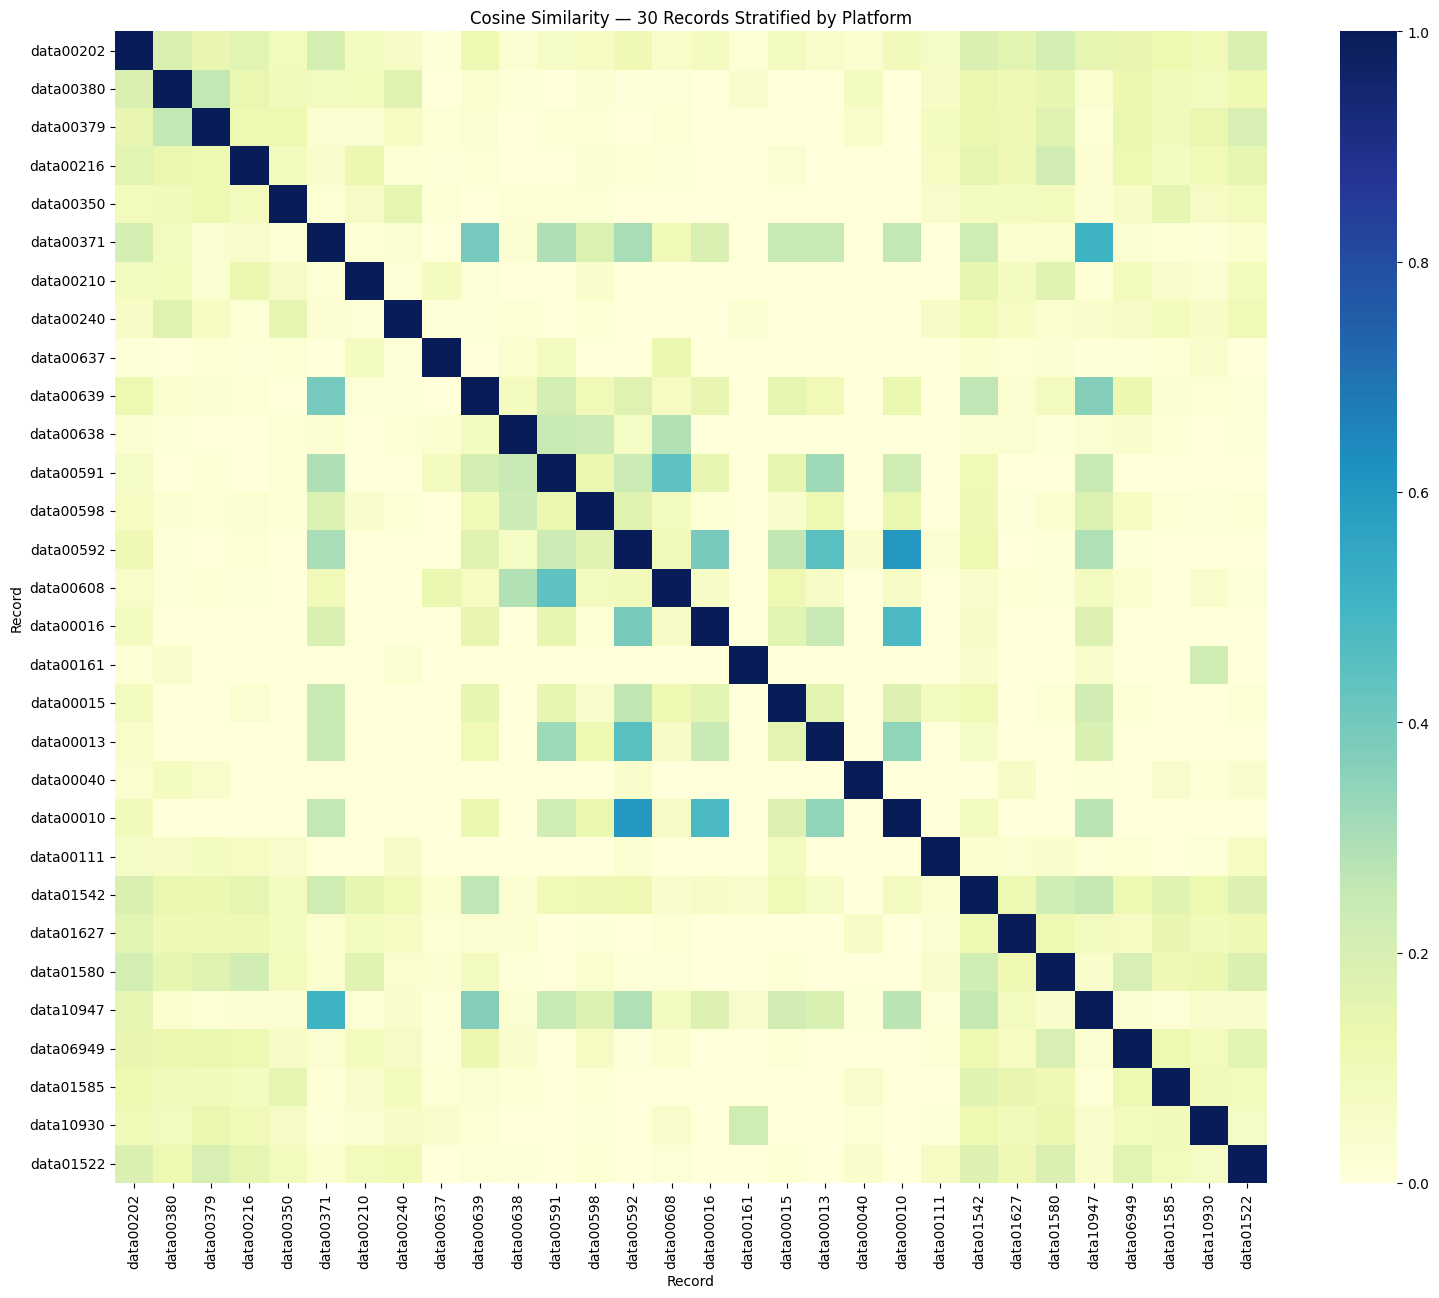

In [17]:
cosine_subset = (
    cosine_df.loc[
        selected_ids,
        selected_ids
    ]
)

plt.figure(
    figsize=(16, 13)
)

sns.heatmap(
    cosine_subset,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Cosine Similarity — 30 Records Stratified by Platform"
)

plt.xlabel("Record")
plt.ylabel("Record")

plt.tight_layout()
plt.show()

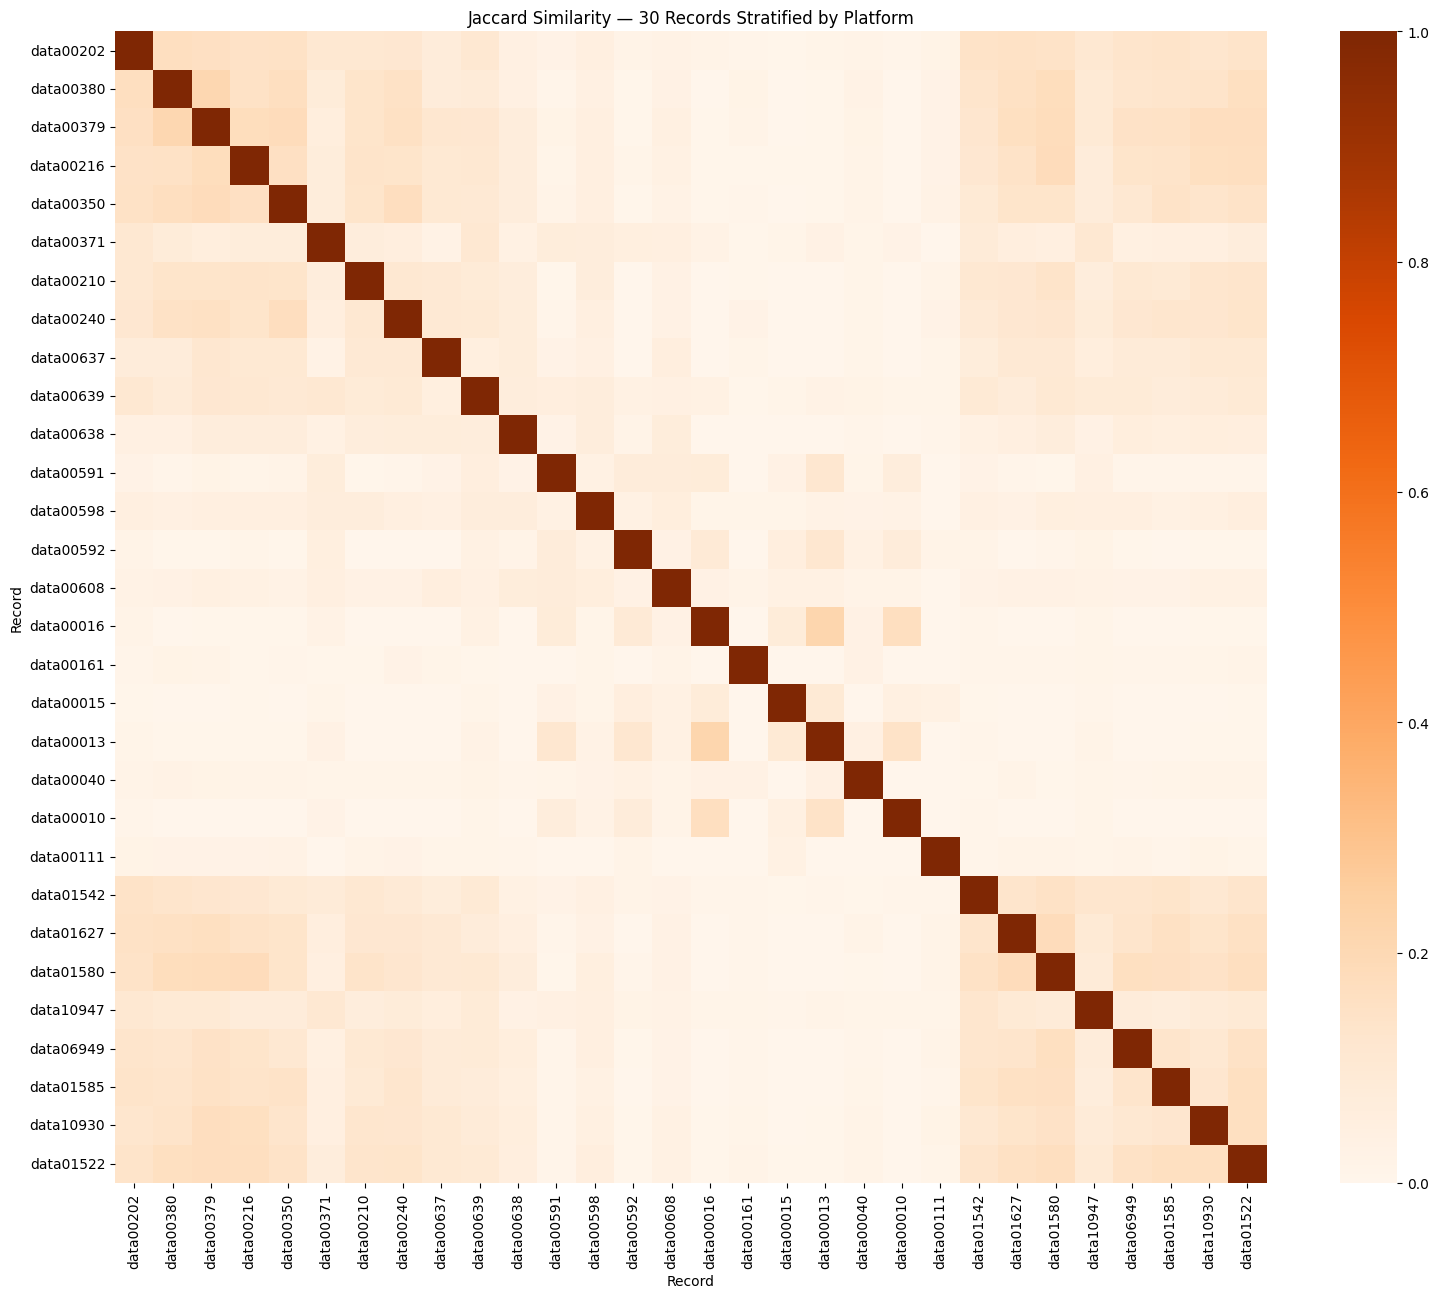

In [18]:
jaccard_subset = (
    jaccard_df.loc[
        selected_ids,
        selected_ids
    ]
)

plt.figure(
    figsize=(16, 13)
)

sns.heatmap(
    jaccard_subset,
    cmap="Oranges",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Jaccard Similarity — 30 Records Stratified by Platform"
)

plt.xlabel("Record")
plt.ylabel("Record")

plt.tight_layout()
plt.show()

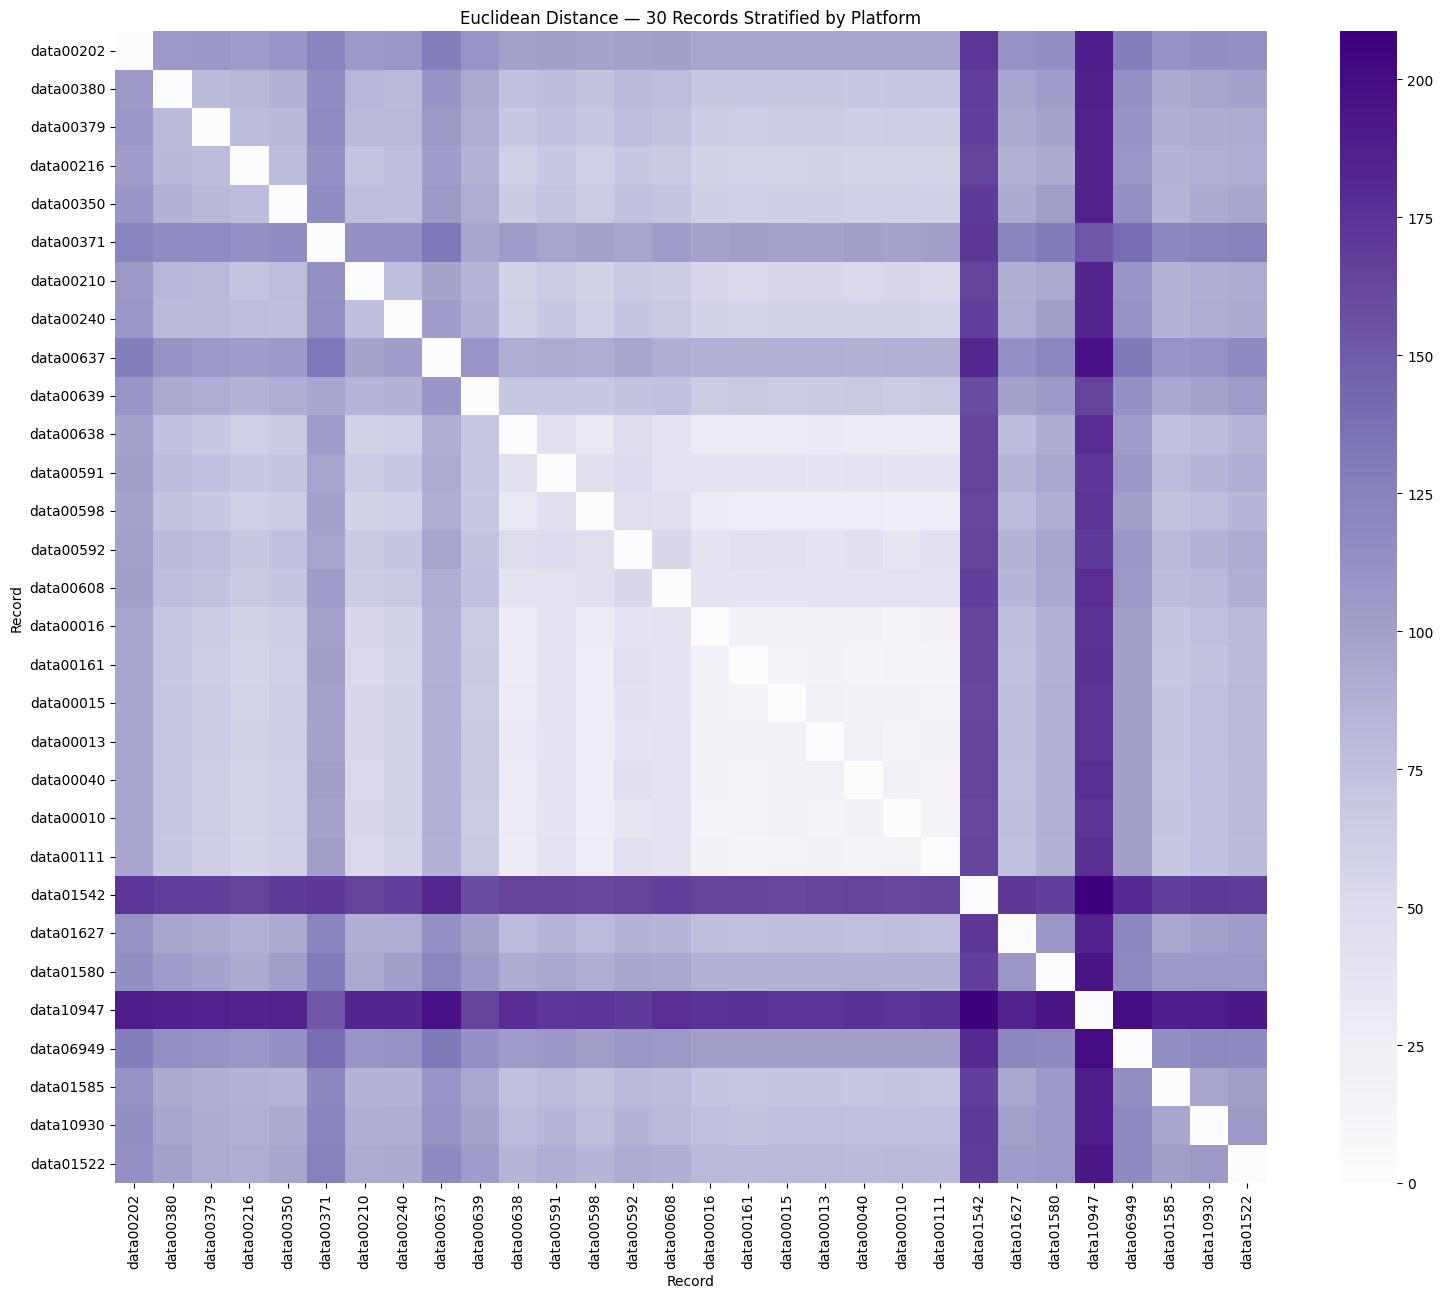

In [19]:
euclidean_subset = (
    euclidean_df.loc[
        selected_ids,
        selected_ids
    ]
)

plt.figure(
    figsize=(16, 13)
)

sns.heatmap(
    euclidean_subset,
    cmap="Purples",
    square=True
)

plt.title(
    "Euclidean Distance — 30 Records Stratified by Platform"
)

plt.xlabel("Record")
plt.ylabel("Record")

plt.tight_layout()
plt.show()


PLATFORM ANALYSIS

Platform record counts:


platform
youtube    91
reddit     82
web        33
tiktok     19
Name: count, dtype: int64


Platforms:
['reddit', 'tiktok', 'web', 'youtube']

Platform cosine similarity:


,reddit,tiktok,web,youtube
reddit,1.000,0.146,0.145,0.505
tiktok,0.146,1.000,0.092,0.176
web,0.145,0.092,1.000,0.170
youtube,0.505,0.176,0.170,1.000



Platform Jaccard similarity:


,reddit,tiktok,web,youtube
reddit,1.000,0.109,0.055,0.253
tiktok,0.109,1.000,0.082,0.089
web,0.055,0.082,1.000,0.043
youtube,0.253,0.089,0.043,1.000



Platform Euclidean distance:


,reddit,tiktok,web,youtube
reddit,0.000,266.513,259.684,315.070
tiktok,266.513,0.000,103.648,347.907
web,259.684,103.648,0.000,346.778
youtube,315.070,347.907,346.778,0.000


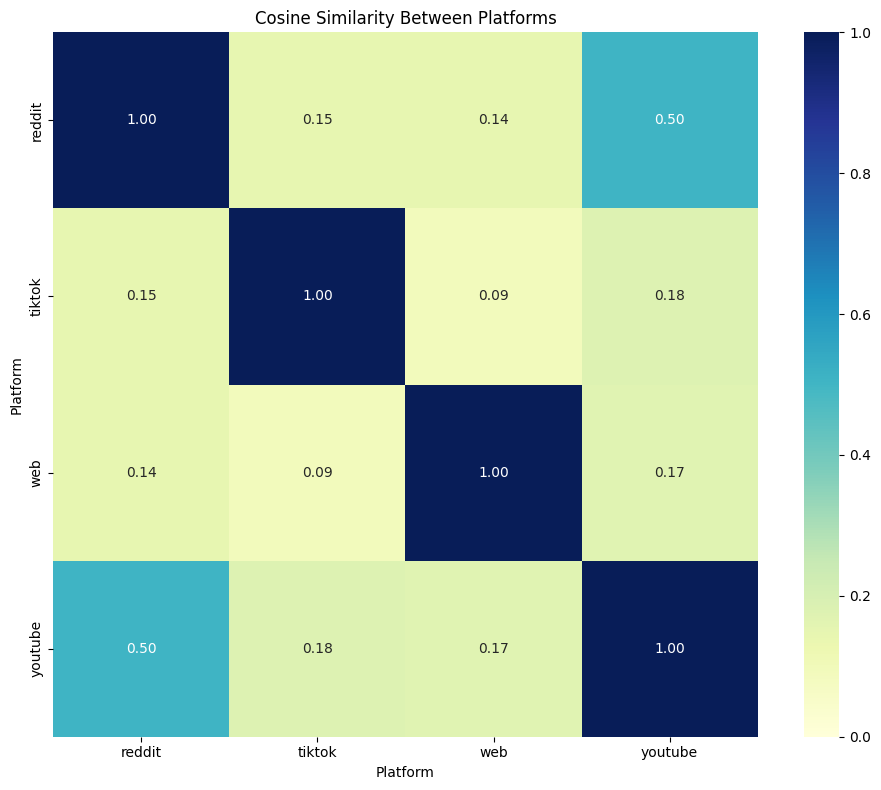

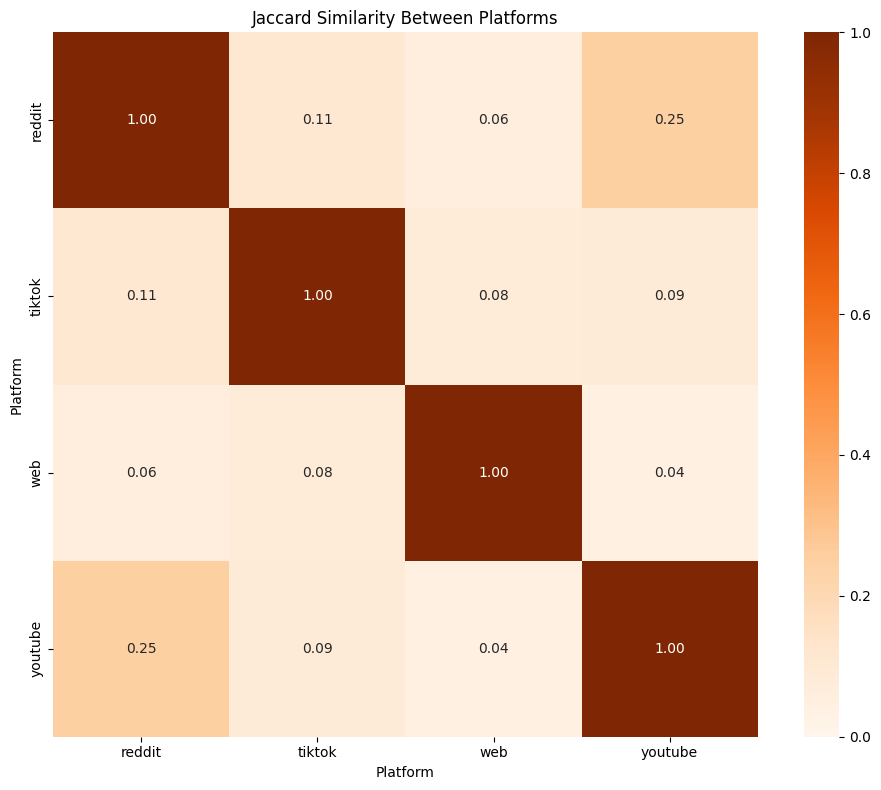

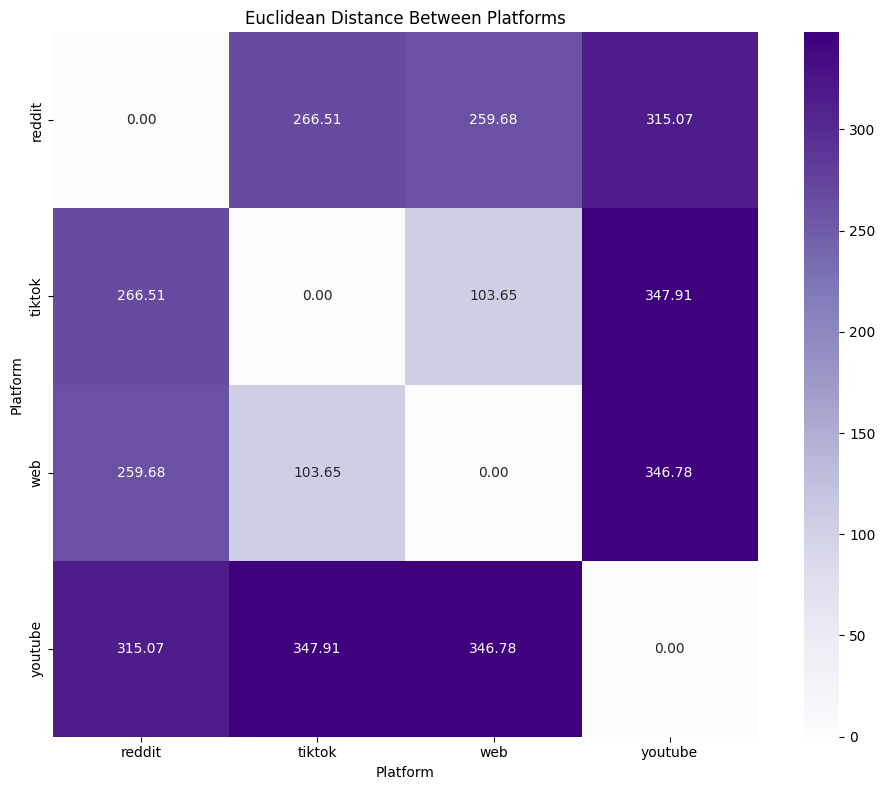

In [20]:
print("\n" + "=" * 70)
print("PLATFORM ANALYSIS")
print("=" * 70)

print("\nPlatform record counts:")

platform_counts = (
    df["platform"]
    .value_counts()
)

display(
    platform_counts
)



platform_documents = (

    df.groupby(
        "platform"
    )["analysis_text"]

    .apply(
        lambda x:
        " ".join(x)
    )
)

print("\nPlatforms:")
print(
    platform_documents.index.tolist()
)



platform_vectorizer = TfidfVectorizer(

    lowercase=True,

    stop_words="english",

    ngram_range=(1, 2),

    norm="l2"
)

platform_tfidf = (

    platform_vectorizer

    .fit_transform(
        platform_documents
    )
)

platform_names = (
    platform_documents
    .index
    .tolist()
)



platform_cosine = (
    cosine_similarity(
        platform_tfidf
    )
)

platform_cosine_df = pd.DataFrame(

    platform_cosine,

    index=platform_names,

    columns=platform_names
)

print("\nPlatform cosine similarity:")
display(
    platform_cosine_df.round(3)
)



platform_word_sets = [

    create_word_set(text)

    for text in platform_documents
]


platform_jaccard = np.zeros(

    (
        len(platform_word_sets),
        len(platform_word_sets)
    )
)


for i in range(
    len(platform_word_sets)
):

    for j in range(
        len(platform_word_sets)
    ):

        platform_jaccard[i, j] = (
            jaccard_similarity(
                platform_word_sets[i],
                platform_word_sets[j]
            )
        )


platform_jaccard_df = pd.DataFrame(

    platform_jaccard,

    index=platform_names,

    columns=platform_names
)


print("\nPlatform Jaccard similarity:")
display(
    platform_jaccard_df.round(3)
)



platform_euclidean_vectorizer = (
    TfidfVectorizer(

        lowercase=True,

        stop_words="english",

        ngram_range=(1, 2),

        norm=None
    )
)


platform_euclidean_tfidf = (

    platform_euclidean_vectorizer

    .fit_transform(
        platform_documents
    )
)


platform_euclidean = (

    euclidean_distances(
        platform_euclidean_tfidf
    )
)


platform_euclidean_df = pd.DataFrame(

    platform_euclidean,

    index=platform_names,

    columns=platform_names
)


print("\nPlatform Euclidean distance:")
display(
    platform_euclidean_df.round(3)
)



plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    platform_cosine_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Cosine Similarity Between Platforms"
)

plt.xlabel("Platform")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    platform_jaccard_df,
    annot=True,
    fmt=".2f",
    cmap="Oranges",
    vmin=0,
    vmax=1,
    square=True
)

plt.title(
    "Jaccard Similarity Between Platforms"
)

plt.xlabel("Platform")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    platform_euclidean_df,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    square=True
)

plt.title(
    "Euclidean Distance Between Platforms"
)

plt.xlabel("Platform")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()

In [21]:
print("\n" + "=" * 70)
print("SEARCH KEYWORD ANALYSIS")
print("=" * 70)


keyword_counts = (
    df["keyword"]
    .value_counts(
        dropna=True
    )
)

print("\nAll search keyword counts:")
display(
    keyword_counts
)


# Keep only keywords with >= 3 records

valid_keywords = (
    keyword_counts[
        keyword_counts >= 3
    ]
    .index
    .tolist()
)

print(
    "\nNumber of Search Keywords with "
    "at least 3 records:",
    len(valid_keywords)
)


search_keyword_df = (
    df[
        df["keyword"].isin(
            valid_keywords
        )
    ]
    .copy()
)


print("\nSearch Keyword record counts:")

search_keyword_counts = (

    search_keyword_df["keyword"]

    .value_counts()

    .rename_axis(
        "search_keyword"
    )

    .reset_index(
        name="records"
    )
)

display(
    search_keyword_counts
)


SEARCH KEYWORD ANALYSIS

All search keyword counts:


keyword
philippine education                      74
philippines education system               9
school facilities philippines              8
digital education philippines              8
deped philippines                          7
education assessment philippines           6
college tuition philippines                5
college education philippines              5
blended learning philippines               5
online learning philippines                5
deped teachers                             4
education curriculum philippines           4
problems in philippine education           4
education challenges philippines           4
classroom problems philippines             3
deped schools                              3
philippines teachers                       3
student struggles philippines              3
college students philippines               2
department of education philippines        2
education inequality filipino students     2
university education philippines           2
ch


Number of Search Keywords with at least 3 records: 18

Search Keyword record counts:


,search_keyword,records
0,philippine education,74
1,philippines education system,9
2,school facilities philippines,8
3,digital education philippines,8
4,deped philippines,7
5,education assessment philippines,6
6,blended learning philippines,5
7,online learning philippines,5
8,college tuition philippines,5
9,college education philippines,5


In [22]:
search_keyword_documents = (

    search_keyword_df

    .groupby(
        "keyword"
    )["analysis_text"]

    .apply(
        lambda x:
        " ".join(x)
    )
)


search_keyword_names = (

    search_keyword_documents

    .index

    .tolist()
)


print(
    "\nSearch Keywords used:"
)

print(
    search_keyword_names
)



Search Keywords used:
['blended learning philippines', 'classroom problems philippines', 'college education philippines', 'college tuition philippines', 'deped philippines', 'deped schools', 'deped teachers', 'digital education philippines', 'education assessment philippines', 'education challenges philippines', 'education curriculum philippines', 'online learning philippines', 'philippine education', 'philippines education system', 'philippines teachers', 'problems in philippine education', 'school facilities philippines', 'student struggles philippines']


In [23]:
search_keyword_vectorizer = (

    TfidfVectorizer(

        lowercase=True,

        stop_words="english",

        ngram_range=(1, 2),

        norm="l2"
    )
)


search_keyword_tfidf = (

    search_keyword_vectorizer

    .fit_transform(
        search_keyword_documents
    )
)

In [24]:
search_keyword_cosine = (

    cosine_similarity(
        search_keyword_tfidf
    )
)


search_keyword_cosine_df = (

    pd.DataFrame(

        search_keyword_cosine,

        index=search_keyword_names,

        columns=search_keyword_names
    )
)


print(
    "\nSearch Keyword cosine similarity:"
)

display(
    search_keyword_cosine_df.round(3)
)



Search Keyword cosine similarity:


,blended learning philippines,classroom problems philippines,college education philippines,college tuition philippines,deped philippines,deped schools,deped teachers,digital education philippines,education assessment philippines,education challenges philippines,education curriculum philippines,online learning philippines,philippine education,philippines education system,philippines teachers,problems in philippine education,school facilities philippines,student struggles philippines
blended learning philippines,1.000,0.002,0.005,0.027,0.041,0.029,0.018,0.040,0.043,0.005,0.089,0.011,0.022,0.034,0.003,0.025,0.010,0.008
classroom problems philippines,0.002,1.000,0.008,0.003,0.004,0.004,0.004,0.021,0.006,0.004,0.002,0.004,0.046,0.013,0.005,0.010,0.013,0.002
college education philippines,0.005,0.008,1.000,0.014,0.011,0.004,0.003,0.040,0.022,0.015,0.025,0.011,0.141,0.096,0.000,0.067,0.017,0.069
college tuition philippines,0.027,0.003,0.014,1.000,0.039,0.047,0.077,0.026,0.013,0.013,0.046,0.049,0.073,0.047,0.004,0.087,0.069,0.023
deped philippines,0.041,0.004,0.011,0.039,1.000,0.029,0.048,0.032,0.023,0.050,0.061,0.028,0.082,0.084,0.039,0.135,0.047,0.036
deped schools,0.029,0.004,0.004,0.047,0.029,1.000,0.082,0.010,0.014,0.005,0.037,0.078,0.062,0.027,0.006,0.095,0.094,0.000
deped teachers,0.018,0.004,0.003,0.077,0.048,0.082,1.000,0.010,0.006,0.003,0.032,0.053,0.063,0.030,0.057,0.085,0.093,0.007
digital education philippines,0.040,0.021,0.040,0.026,0.032,0.010,0.010,1.000,0.022,0.014,0.025,0.016,0.141,0.127,0.020,0.052,0.021,0.073
education assessment philippines,0.043,0.006,0.022,0.013,0.023,0.014,0.006,0.022,1.000,0.004,0.091,0.009,0.044,0.034,0.008,0.029,0.025,0.015
education challenges philippines,0.005,0.004,0.015,0.013,0.050,0.005,0.003,0.014,0.004,1.000,0.008,0.007,0.086,0.077,0.000,0.064,0.013,0.037


In [25]:
search_keyword_word_sets = [

    create_word_set(text)

    for text in search_keyword_documents
]


search_keyword_jaccard = np.zeros(

    (
        len(search_keyword_word_sets),
        len(search_keyword_word_sets)
    )
)


for i in range(
    len(search_keyword_word_sets)
):

    for j in range(
        len(search_keyword_word_sets)
    ):

        search_keyword_jaccard[i, j] = (

            jaccard_similarity(

                search_keyword_word_sets[i],

                search_keyword_word_sets[j]
            )
        )


search_keyword_jaccard_df = (

    pd.DataFrame(

        search_keyword_jaccard,

        index=search_keyword_names,

        columns=search_keyword_names
    )
)


print(
    "\nSearch Keyword Jaccard similarity:"
)

display(
    search_keyword_jaccard_df.round(3)
)


Search Keyword Jaccard similarity:


,blended learning philippines,classroom problems philippines,college education philippines,college tuition philippines,deped philippines,deped schools,deped teachers,digital education philippines,education assessment philippines,education challenges philippines,education curriculum philippines,online learning philippines,philippine education,philippines education system,philippines teachers,problems in philippine education,school facilities philippines,student struggles philippines
blended learning philippines,1.000,0.048,0.119,0.081,0.095,0.059,0.047,0.096,0.122,0.104,0.109,0.065,0.028,0.038,0.070,0.064,0.065,0.065
classroom problems philippines,0.048,1.000,0.036,0.014,0.052,0.016,0.022,0.033,0.027,0.034,0.052,0.024,0.009,0.010,0.045,0.013,0.025,0.018
college education philippines,0.119,0.036,1.000,0.045,0.072,0.016,0.037,0.159,0.088,0.119,0.065,0.107,0.071,0.088,0.041,0.131,0.088,0.145
college tuition philippines,0.081,0.014,0.045,1.000,0.077,0.084,0.072,0.041,0.062,0.040,0.082,0.061,0.014,0.016,0.060,0.040,0.054,0.021
deped philippines,0.095,0.052,0.072,0.077,1.000,0.054,0.089,0.073,0.066,0.063,0.089,0.074,0.026,0.031,0.065,0.057,0.075,0.043
deped schools,0.059,0.016,0.016,0.084,0.054,1.000,0.067,0.020,0.044,0.015,0.077,0.063,0.012,0.012,0.033,0.033,0.047,0.004
deped teachers,0.047,0.022,0.037,0.072,0.089,0.067,1.000,0.044,0.017,0.022,0.076,0.053,0.016,0.019,0.057,0.038,0.057,0.022
digital education philippines,0.096,0.033,0.159,0.041,0.073,0.020,0.044,1.000,0.080,0.114,0.064,0.104,0.074,0.090,0.037,0.114,0.066,0.125
education assessment philippines,0.122,0.027,0.088,0.062,0.066,0.044,0.017,0.080,1.000,0.065,0.158,0.060,0.019,0.022,0.087,0.040,0.069,0.047
education challenges philippines,0.104,0.034,0.119,0.040,0.063,0.015,0.022,0.114,0.065,1.000,0.053,0.093,0.050,0.059,0.028,0.090,0.069,0.102


In [26]:
search_keyword_euclidean_vectorizer = (

    TfidfVectorizer(

        lowercase=True,

        stop_words="english",

        ngram_range=(1, 2),

        norm=None
    )
)


search_keyword_euclidean_tfidf = (

    search_keyword_euclidean_vectorizer

    .fit_transform(
        search_keyword_documents
    )
)


search_keyword_euclidean = (

    euclidean_distances(
        search_keyword_euclidean_tfidf
    )
)


search_keyword_euclidean_df = (

    pd.DataFrame(

        search_keyword_euclidean,

        index=search_keyword_names,

        columns=search_keyword_names
    )
)


print(
    "\nSearch Keyword Euclidean distance:"
)

display(
    search_keyword_euclidean_df.round(3)
)


Search Keyword Euclidean distance:


,blended learning philippines,classroom problems philippines,college education philippines,college tuition philippines,deped philippines,deped schools,deped teachers,digital education philippines,education assessment philippines,education challenges philippines,education curriculum philippines,online learning philippines,philippine education,philippines education system,philippines teachers,problems in philippine education,school facilities philippines,student struggles philippines
blended learning philippines,0.000,37.270,68.911,41.665,49.682,44.800,51.522,77.252,39.448,66.941,41.740,98.214,458.633,273.048,34.808,166.824,83.953,117.509
classroom problems philippines,37.270,0.000,63.915,33.367,43.576,37.337,45.052,73.661,30.836,61.835,35.262,95.021,457.732,272.666,23.345,165.436,79.945,114.854
college education philippines,68.911,63.915,0.000,66.679,72.304,69.006,73.467,92.242,65.345,84.259,67.341,110.890,453.637,273.271,62.659,171.637,98.214,125.014
college tuition philippines,41.665,33.367,66.679,0.000,47.022,41.310,47.473,75.973,36.473,64.675,39.521,95.835,457.038,272.341,30.593,164.431,80.781,115.970
deped philippines,49.682,43.576,72.304,47.022,0.000,50.064,55.329,80.514,45.740,69.136,47.777,100.091,456.658,271.803,41.046,163.906,85.567,118.582
deped schools,44.800,37.337,69.006,41.310,50.064,0.000,49.929,78.194,40.103,66.986,43.019,96.157,457.345,273.282,34.880,164.599,81.460,117.792
deped teachers,51.522,45.052,73.467,47.473,55.329,49.929,0.000,82.089,47.490,71.616,49.776,99.755,457.473,274.099,42.353,166.103,84.550,120.201
digital education philippines,77.252,73.661,92.242,75.973,80.514,78.194,82.089,0.000,75.092,92.053,76.791,116.597,453.715,272.553,72.578,175.952,104.669,129.494
education assessment philippines,39.448,30.836,65.345,36.473,45.740,40.103,47.490,75.092,0.000,63.664,36.680,96.089,457.795,272.523,27.810,165.626,81.045,115.527
education challenges philippines,66.941,61.835,84.259,64.675,69.136,66.986,71.616,92.053,63.664,0.000,65.771,109.865,456.905,274.113,60.459,171.140,97.041,125.780


In [27]:
search_keyword_cosine_dissimilarity_df = (

    1 - search_keyword_cosine_df
)

search_keyword_jaccard_dissimilarity_df = (

    1 - search_keyword_jaccard_df
)

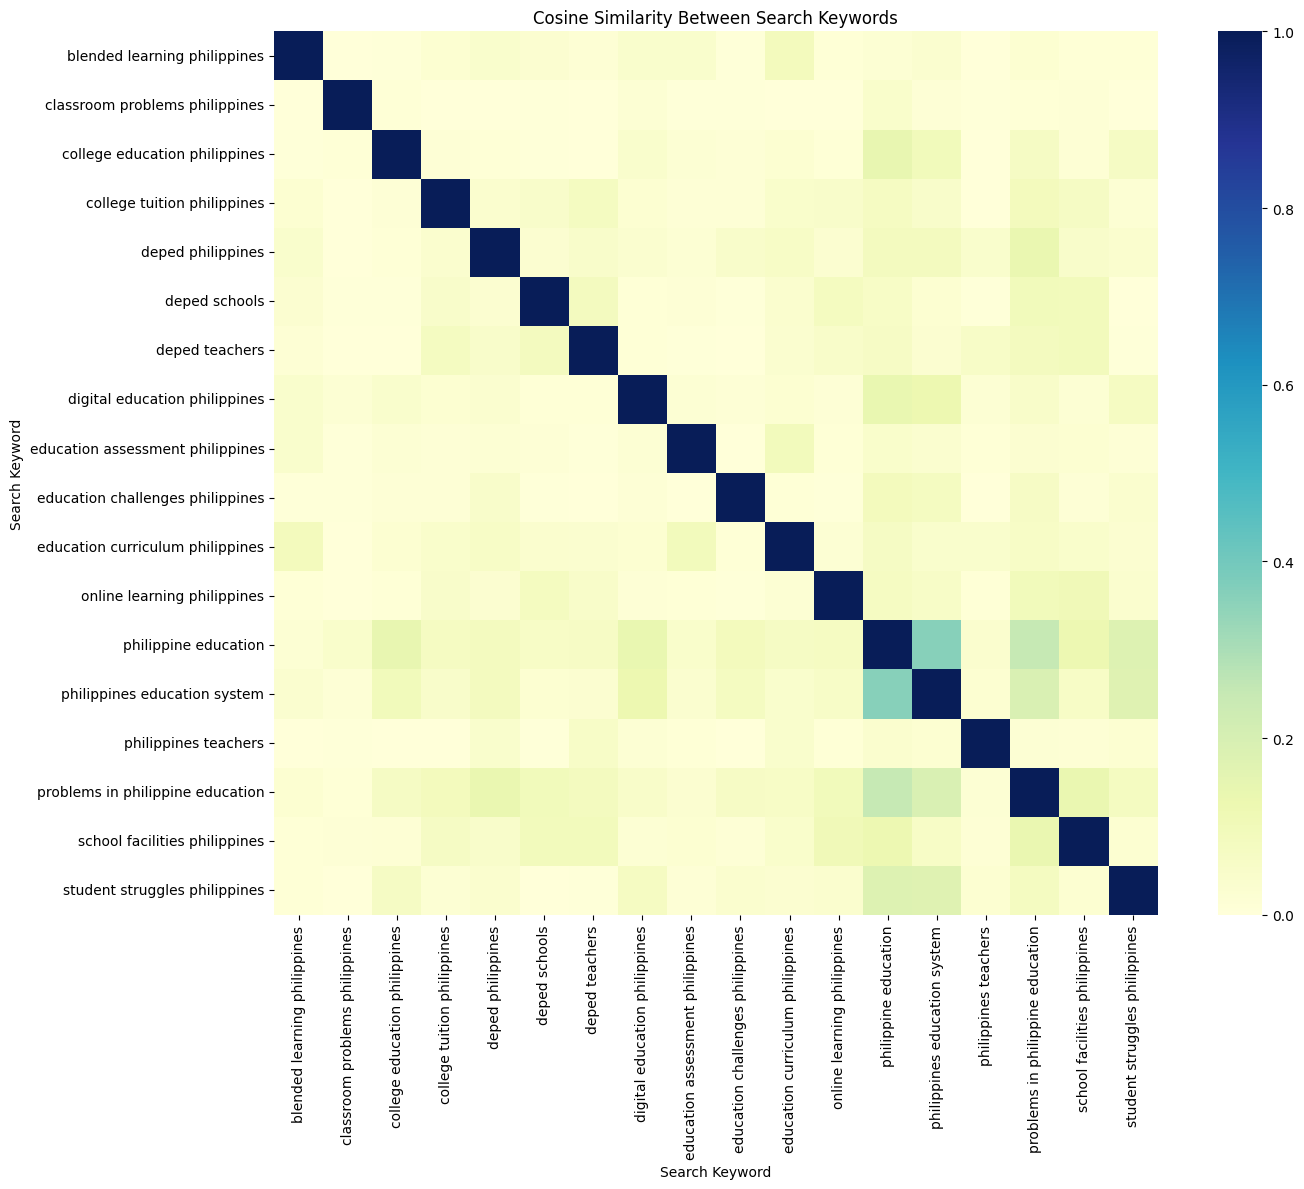

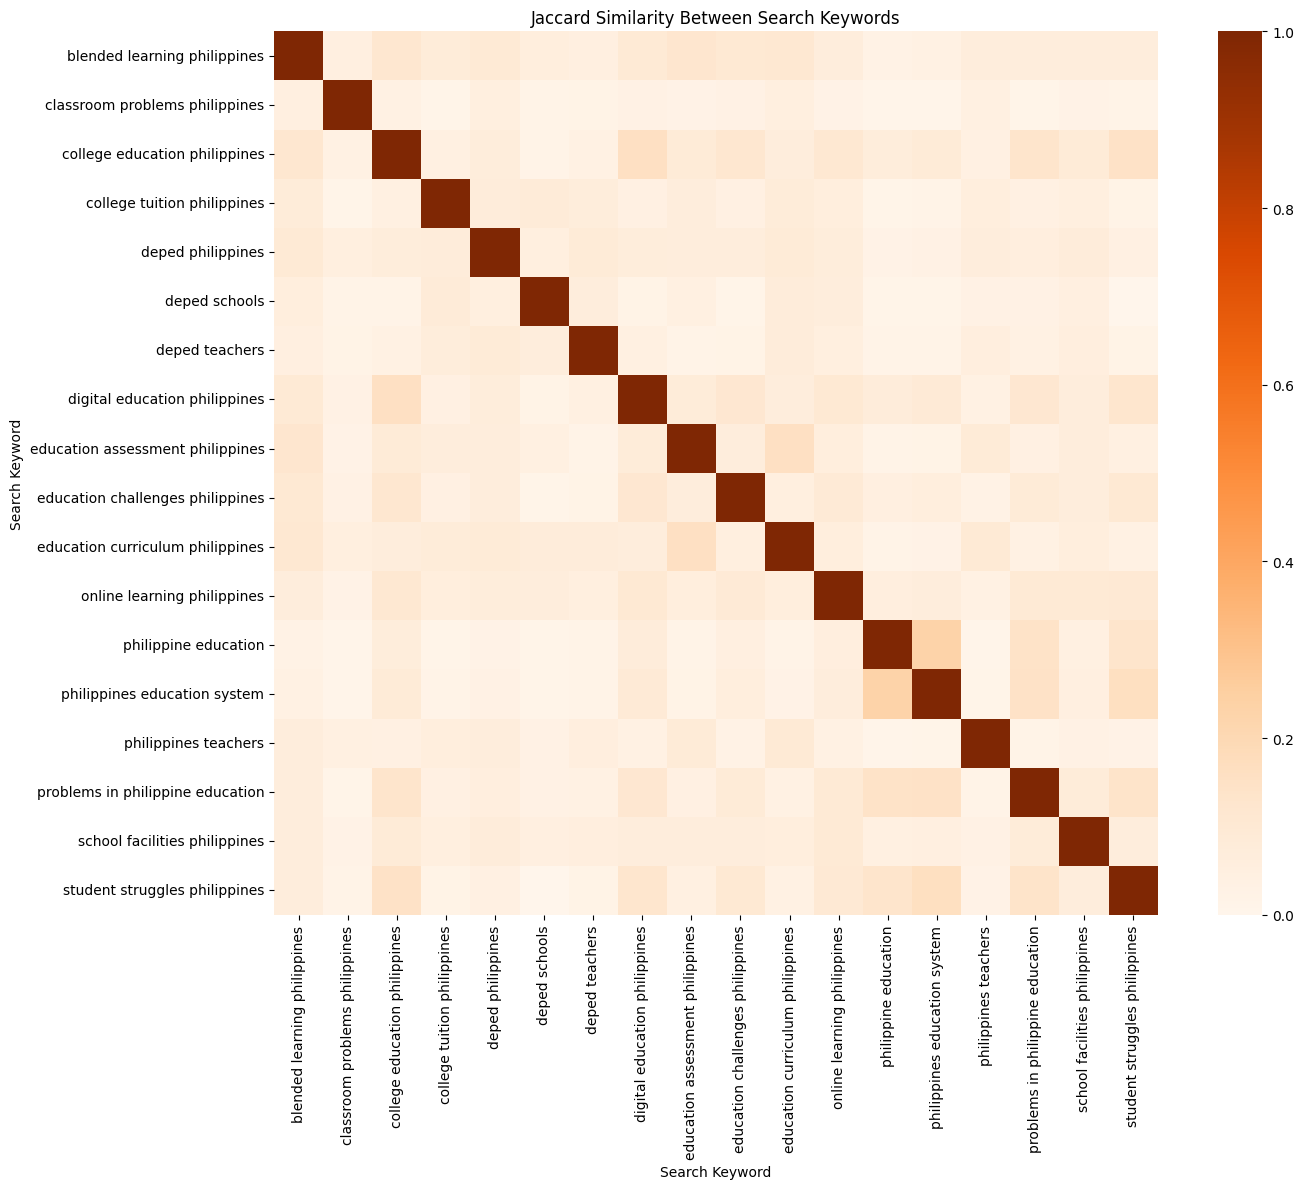

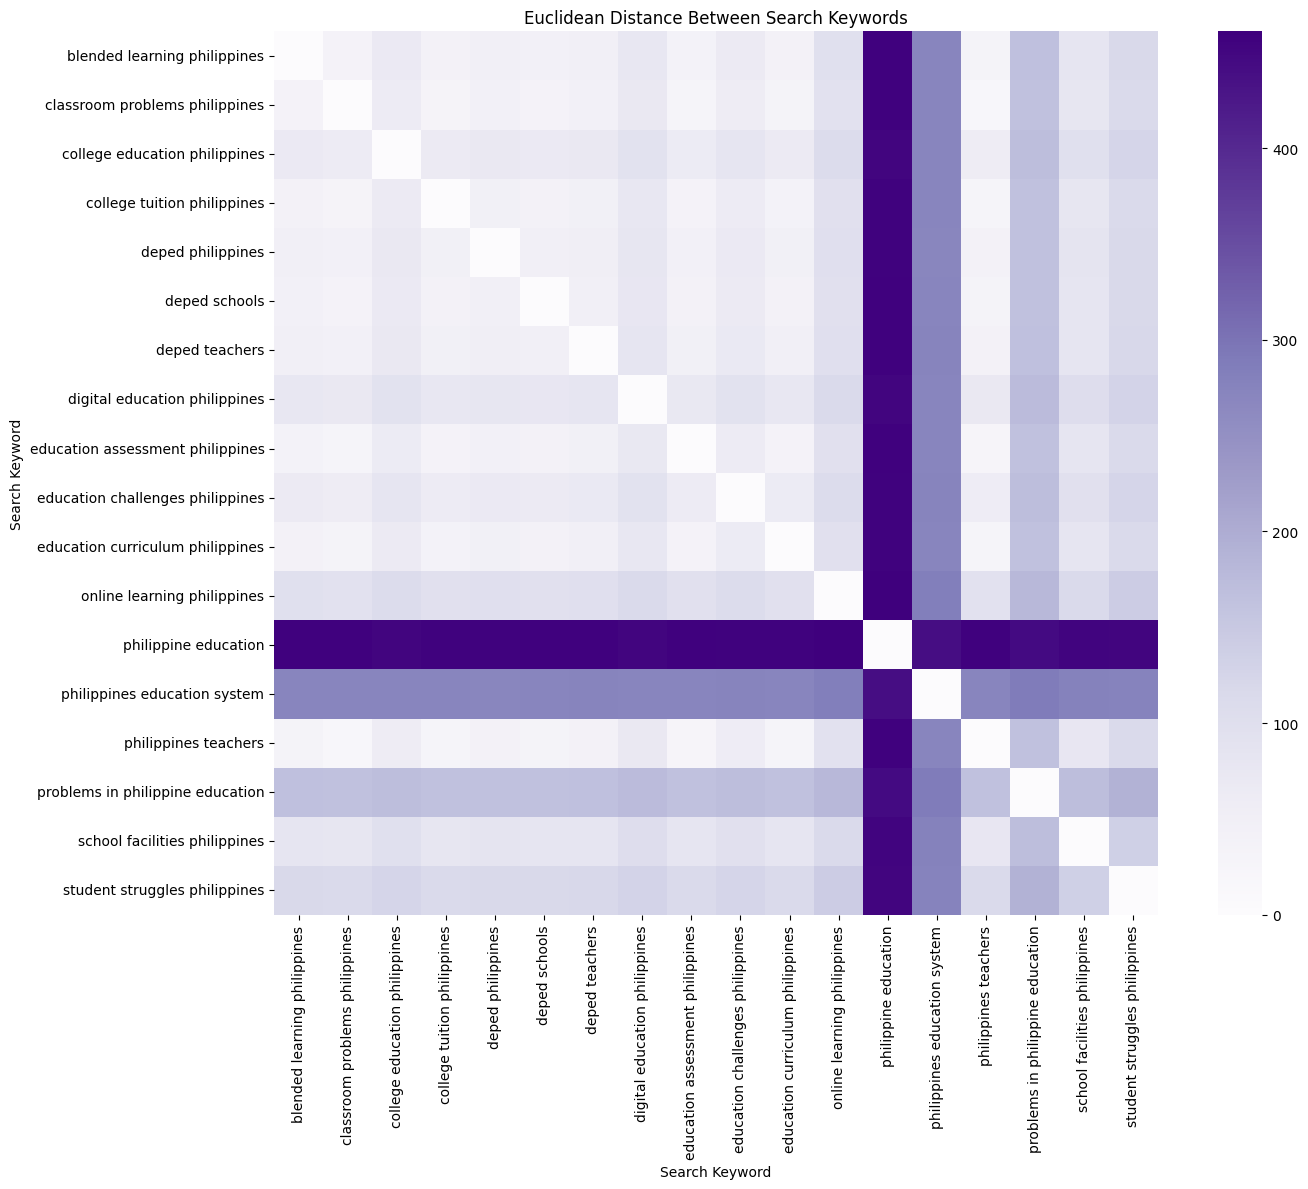

In [28]:
plt.figure(
    figsize=(15, 12)
)

sns.heatmap(

    search_keyword_cosine_df,

    cmap="YlGnBu",

    vmin=0,

    vmax=1,

    square=True,

    annot=False
)

plt.title(
    "Cosine Similarity Between Search Keywords"
)

plt.xlabel(
    "Search Keyword"
)

plt.ylabel(
    "Search Keyword"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(15, 12)
)

sns.heatmap(

    search_keyword_jaccard_df,

    cmap="Oranges",

    vmin=0,

    vmax=1,

    square=True,

    annot=False
)

plt.title(
    "Jaccard Similarity Between Search Keywords"
)

plt.xlabel(
    "Search Keyword"
)

plt.ylabel(
    "Search Keyword"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(15, 12)
)

sns.heatmap(

    search_keyword_euclidean_df,

    cmap="Purples",

    square=True,

    annot=False
)

plt.title(
    "Euclidean Distance Between Search Keywords"
)

plt.xlabel(
    "Search Keyword"
)

plt.ylabel(
    "Search Keyword"
)

plt.tight_layout()
plt.show()


In [29]:
print("\n" + "=" * 70)
print("TOP SEARCH KEYWORD PAIRS")
print("=" * 70)


search_keyword_pairs = get_top_pairs(

    search_keyword_cosine_df,

    "cosine_similarity",

    n=20,

    ascending=False
)

display(
    search_keyword_pairs
)


TOP SEARCH KEYWORD PAIRS


,record_1,record_2,cosine_similarity
138,philippine education,philippines education system,0.360698
140,philippine education,problems in philippine education,0.252432
144,philippines education system,problems in philippine education,0.194661
142,philippine education,student struggles philippines,0.177147
146,philippines education system,student struggles philippines,0.174492
42,college education philippines,philippine education,0.141125
102,digital education philippines,philippine education,0.140593
150,problems in philippine education,school facilities philippines,0.136496
72,deped philippines,problems in philippine education,0.134936
103,digital education philippines,philippines education system,0.127246


In [30]:
def compare_metrics(
    record_id_1,
    record_id_2
):

    cosine_value = (
        cosine_df.loc[
            record_id_1,
            record_id_2
        ]
    )

    jaccard_value = (
        jaccard_df.loc[
            record_id_1,
            record_id_2
        ]
    )

    return {

        "Record 1":
            record_id_1,

        "Record 2":
            record_id_2,

        "Cosine Similarity":
            cosine_value,

        "Cosine Dissimilarity":
            1 - cosine_value,

        "Jaccard Similarity":
            jaccard_value,

        "Jaccard Dissimilarity":
            1 - jaccard_value,

        "Euclidean Distance":
            euclidean_df.loc[
                record_id_1,
                record_id_2
            ]
    }


pair = compare_metrics(

    df.iloc[0]["record_id"],

    df.iloc[1]["record_id"]
)


print("\nExample record comparison:")

display(
    pd.DataFrame(
        [pair]
    ).round(4)
)


Example record comparison:


,Record 1,Record 2,Cosine Similarity,Cosine Dissimilarity,Jaccard Similarity,Jaccard Dissimilarity,Euclidean Distance
0,data14114,data12313,0.0169,0.9831,0.0515,0.9485,36.4415


In [31]:
print("\n" + "=" * 70)
print("REMARKS AND INTERPRETATION")
print("=" * 70)


remarks = [

    (
        "Dataset",
        "The official 180-record dataset is used. "
        "The script checks that exactly 180 records are loaded."
    ),

    (
        "Text preparation",
        "The damaged lemmas column is not used. "
        "Original text/title fields are used instead."
    ),

    (
        "Comments",
        "Reddit and YouTube comments are compared using "
        "comment text only. Parent titles are excluded."
    ),

    (
        "Articles and Reddit posts",
        "Articles and Reddit posts use their own titles "
        "rather than parent titles."
    ),

    (
        "Duplicate candidate",
        "data00396 and data00327 no longer produce the old "
        "0.92 similarity after title leakage is removed. "
        "The corrected values should be used for manual verification."
    ),

    (
        "Reddit grouping",
        "Reddit public post page and Reddit public search "
        "are collection methods, so they are merged under "
        "the Reddit platform."
    ),

    (
        "Search Keyword",
        "The keyword field represents search keywords rather "
        "than discovered topics. Only keywords with at least "
        "3 records are included in the group analysis."
    ),

    (
        "Uneven platform sizes",
        "Platform comparisons use group-level TF-IDF centroids "
        "for cosine and Euclidean calculations. Jaccard uses "
        "average pairwise similarity."
    ),

    (
        "Euclidean distance",
        "Euclidean distance uses unnormalized TF-IDF "
        "(norm=None), so it is not simply a restatement "
        "of cosine distance on normalized vectors."
    ),

    (
        "Dissimilarity",
        "Cosine and Jaccard dissimilarity are calculated as "
        "1 minus similarity."
    ),

    (
        "Most dissimilar records",
        "An arbitrary bottom-20 table is not reported because "
        "many record pairs have exactly zero similarity. "
        "Instead, average similarity and the percentage of "
        "zero-similarity pairs are reported."
    ),

    (
        "Record heatmap",
        "The 30-record heatmap is selected across platforms "
        "rather than simply taking the 30 longest records. "
        "This prevents articles from dominating the visualization."
    ),

    (
        "Search Keyword heatmap",
        "Numerical annotations are removed because the "
        "keyword matrices are too crowded to read clearly."
    )
]


remarks_df = pd.DataFrame(

    remarks,

    columns=[
        "Item",
        "Interpretation"
    ]
)


display(
    remarks_df
)


REMARKS AND INTERPRETATION


,Item,Interpretation
0,Dataset,The official 180-record dataset is used. The script checks that exactly 180 records are loaded.
1,Text preparation,The damaged lemmas column is not used. Original text/title fields are used instead.
2,Comments,Reddit and YouTube comments are compared using comment text only. Parent titles are excluded.
3,Articles and Reddit posts,Articles and Reddit posts use their own titles rather than parent titles.
4,Duplicate candidate,data00396 and data00327 no longer produce the old 0.92 similarity after title leakage is removed...
5,Reddit grouping,"Reddit public post page and Reddit public search are collection methods, so they are merged unde..."
6,Search Keyword,The keyword field represents search keywords rather than discovered topics. Only keywords with a...
7,Uneven platform sizes,Platform comparisons use group-level TF-IDF centroids for cosine and Euclidean calculations. Jac...
8,Euclidean distance,"Euclidean distance uses unnormalized TF-IDF (norm=None), so it is not simply a restatement of co..."
9,Dissimilarity,Cosine and Jaccard dissimilarity are calculated as 1 minus similarity.


In [32]:
print("\n" + "=" * 70)
print("SAVING RESULTS")
print("=" * 70)


# Record-level matrices

cosine_df.to_csv(
    "record_cosine_similarity.csv"
)

cosine_dissimilarity_df.to_csv(
    "record_cosine_dissimilarity.csv"
)

jaccard_df.to_csv(
    "record_jaccard_similarity.csv"
)

jaccard_dissimilarity_df.to_csv(
    "record_jaccard_dissimilarity.csv"
)

euclidean_df.to_csv(
    "record_euclidean_distance.csv"
)


# Summary

similarity_summary.to_csv(
    "record_similarity_summary.csv",
    index=False
)


# Top pairs

top_cosine_detailed.to_csv(
    "top20_cosine_pairs.csv",
    index=False
)

top_jaccard_detailed.to_csv(
    "top20_jaccard_pairs.csv",
    index=False
)

top_euclidean_detailed.to_csv(
    "top20_euclidean_pairs.csv",
    index=False
)


# Duplicate

duplicate_check.to_csv(
    "duplicate_candidate_check.csv",
    index=False
)


# Platform

platform_counts.to_csv(
    "platform_counts.csv"
)

platform_cosine_df.to_csv(
    "platform_cosine_similarity.csv"
)

platform_jaccard_df.to_csv(
    "platform_jaccard_similarity.csv"
)

platform_euclidean_df.to_csv(
    "platform_euclidean_distance.csv"
)


# Search Keyword

search_keyword_counts.to_csv(
    "search_keyword_counts.csv",
    index=False
)

search_keyword_cosine_df.to_csv(
    "search_keyword_cosine_similarity.csv"
)

search_keyword_jaccard_df.to_csv(
    "search_keyword_jaccard_similarity.csv"
)

search_keyword_euclidean_df.to_csv(
    "search_keyword_euclidean_distance.csv"
)

search_keyword_cosine_dissimilarity_df.to_csv(
    "search_keyword_cosine_dissimilarity.csv"
)

search_keyword_jaccard_dissimilarity_df.to_csv(
    "search_keyword_jaccard_dissimilarity.csv"
)


# Remarks

remarks_df.to_csv(
    "remarks.csv",
    index=False
)


# Record overview

df[
    [
        "record_id",
        "record_type",
        "platform",
        "source_name",
        "keyword",
        "title",
        "analysis_text",
        "text_length"
    ]
].to_csv(
    "record_text_overview.csv",
    index=False
)


SAVING RESULTS


In [33]:
print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(
    "\nRecords analyzed:",
    len(df)
)

print(
    "\nPlatform counts:"
)

display(
    df["platform"]
    .value_counts()
)


print(
    "\nAverage Cosine Similarity:",
    round(
        cosine_values.mean(),
        4
    )
)

print(
    "Cosine zero-similarity pairs:",
    round(
        (
            cosine_values == 0
        ).mean() * 100,
        2
    ),
    "%"
)

print(
    "\nAverage Jaccard Similarity:",
    round(
        jaccard_values.mean(),
        4
    )
)

print(
    "Jaccard zero-similarity pairs:",
    round(
        (
            jaccard_values == 0
        ).mean() * 100,
        2
    ),
    "%"
)

print(
    "\nAverage Euclidean Distance:",
    round(
        euclidean_values.mean(),
        4
    )
)

print(
    "\nSearch Keywords retained:",
    len(valid_keywords)
)

print(
    "\nDuplicate check:"
)

display(
    duplicate_check.round(4)
)


print("\n" + "=" * 70)
print("CORRECTED ANALYSIS COMPLETED")
print("=" * 70)


FINAL SUMMARY

Records analyzed: 225

Platform counts:


platform
youtube    91
reddit     82
web        33
tiktok     19
Name: count, dtype: int64


Average Cosine Similarity: 0.024
Cosine zero-similarity pairs: 63.5 %

Average Jaccard Similarity: 0.0319
Jaccard zero-similarity pairs: 35.7 %

Average Euclidean Distance: 42.1549

Search Keywords retained: 18

Duplicate check:


,record_1,record_2,cosine_similarity,cosine_dissimilarity,jaccard_similarity,jaccard_dissimilarity,note
0,data00396,data00327,0.0,1.0,0.0,1.0,Old 0.92 result was caused by title leakage. Corrected analysis compares the actual record text.



CORRECTED ANALYSIS COMPLETED
